# Predicting Boston Home Values with Alternative Data

**Question.** How well can a listing's own characteristics, combined with neighbourhood-level "alternative data" (crime, census population, walkability, school proximity), predict the **price per square foot** of Boston for-sale listings, and what carries the signal once property size is removed?

### Data
1. **Listings:** residential for-sale listings in Boston, MA, with an estimated monthly payment (529 listings with a ZIP code; 515 used for modelling after cleaning).
2. **Crime layer:** Boston Police incident reports, aggregated to incidents per capita at the ZIP level.
3. **Demographics layer:** 2020 Decennial Census total population by ZIP code (ZCTA).

### Approach
Audit and clean the listings, log-transform the target, then compare OLS, Elastic Net, Random Forest, XGBoost and AdaBoost (a hand-written AdaBoost.R2) with 5-fold cross-validation, tune the three tree models with nested cross-validation, and interpret the forest with variable importance and a shallow tree.

### Statistical hygiene & assumptions
- **No look-ahead:** missing values are imputed inside each cross-validation fold, using that fold's training rows only. Hyperparameters are tuned with nested cross-validation, so held-out folds never influence tuning.
- **Leakage control:** the listing price and monthly payment are kept only for scoring and are excluded from every model's predictors (payment is roughly 0.64% of price, and price is the numerator of the target).
- **Temporal alignment:** ZIP-level features (crime and population) are assumed stable across the 2020-2025 cross-section.

### Headline results (5-fold CV, error on the log price-per-sqft scale)
| Model | RMSLE (fixed settings) | RMSLE (tuned) |
|---|---|---|
| OLS | 0.342 | n/a |
| Elastic Net | 0.338 | n/a |
| Random Forest | 0.253 | 0.251 |
| **XGBoost** | **0.253** | **0.247** |
| AdaBoost | 0.274 | 0.260 |

RMSLE is the typical *proportional* error, so 0.25 means a typical miss of roughly a quarter of the true price per square foot. The tree models clearly beat the linear baselines; differences among the tree models are small relative to fold-to-fold noise. Details, the full tables and the limitations are below.

In [1]:
## Install any missing packages, then load them.
needed <- c("dplyr", "tidyr", "stringr", "readr", "ggplot2", "scales", "janitor", "glmnet", "caret",
            "randomForest", "rpart", "rpart.plot", "corrplot", "xgboost", "recipes")
to_install <- setdiff(needed, rownames(installed.packages()))
if (length(to_install) > 0) install.packages(to_install)

library(rpart.plot)
library(randomForest)
library(tidyr)
library(glmnet)
library(dplyr)
library(ggplot2)
library(janitor)
library(stringr)
library(caret)
library(recipes)

Warning message:
“package ‘rpart.plot’ was built under R version 4.6.1”


Loading required package: rpart



randomForest 4.7-1.2



Type rfNews() to see new features/changes/bug fixes.



Warning message:
“package ‘glmnet’ was built under R version 4.6.1”


...

Warning message:
“package ‘recipes’ was built under R version 4.6.1”



Attaching package: ‘recipes’




The following object is masked from ‘package:stringr’:

    fixed




The following object is masked from ‘package:Matrix’:

    update




The following object is masked from ‘package:stats’:

    step




In [2]:
## The three data files sit next to this notebook (see the README for what each one is).
data_files <- c(housing = "housing.csv",
                crime   = "Boston_Incidents.csv",
                census  = "DECENNIALDHC2020.P1-2026-10-19T233433.csv")
missing_files <- data_files[!file.exists(data_files)]
if (length(missing_files) > 0) stop("Missing data file(s) next to the notebook: ", paste(missing_files, collapse = ", "))

d       <- read.csv(data_files[["housing"]])  # residential listings
crime   <- read.csv(data_files[["crime"]])    # police incident reports

## 2020 Census population by ZIP (data.census.gov, table P1). The download is "wide":
## one column per ZCTA5 and a single "Total" row.
pop_raw <- read.csv(data_files[["census"]], check.names = FALSE)

d <- d %>%
  select(-url, -image_url, -nearby_cities, -X, -X.1) %>% #removing irrelevant or NA-filled columns
  filter(grepl("Boston, MA", address, ignore.case = TRUE)) #filtering for Boston, MA houses

crime <- crime %>%
  janitor::clean_names() %>%
  select(-objectid, -incident_number) %>%
  filter(zip_code != "", !is.na(zip_code)) %>%
  filter(year != 2025)

## Reshape to one row per ZIP. Counts are strings with thousands separators ("4,228"), so strip the commas.
pop <- data.frame(NAME = names(pop_raw)[-1],
                  P1_001N = unname(unlist(pop_raw[1, -1]))) %>%
  mutate(zip_code = stringr::str_extract(NAME, "\\b\\d{5}\\b"),
         zipPop = as.integer(gsub(",", "", P1_001N))) %>%
  select(zip_code, zipPop)

Warning message in read.table(file = file, header = header, sep = sep, quote = quote, :
“incomplete final line found by readTableHeader on 'DECENNIALDHC2020.P1-2026-10-19T233433.csv'”


#EDA and Feature Engineering

##Data Cleaning

In [3]:
## Extract the 5-digit zip code from the 'address' column in the housing data (d)

d <- d %>%
mutate(zip_code = stringr::str_extract(address, "\\b\\d{5}\\b")) %>%
filter(!is.na(zip_code))

## Aggregate the crime data to count the total number of incidents per zip code

crime_summary <- crime %>%
group_by(zip_code) %>%
summarize(incident_count = n(), .groups = 'drop')

## Each lookup table must have one row per ZIP, otherwise the joins would duplicate houses.
stopifnot(!anyDuplicated(crime_summary$zip_code), !anyDuplicated(pop$zip_code))
n_before_merge <- nrow(d)

## Perform a left join to attach the crime count to each house in the housing data. This results in our final data frame: merged_data.

merged_data <- d %>%
left_join(crime_summary, by = "zip_code") %>%
left_join(pop, by = "zip_code") %>%
filter(!is.na(zipPop)) #filtering out if there was no match

## Merge check: left joins must not add rows. Houses are only lost to the zipPop filter above.
stopifnot(nrow(merged_data) <= n_before_merge)
cat("Boston listings with a ZIP:", n_before_merge, "| after merging crime and population:", nrow(merged_data),
    "| dropped (no population match):", n_before_merge - nrow(merged_data), "\n")
cat("Houses with no crime match:", sum(is.na(merged_data$incident_count)), "\n")

Boston listings with a ZIP: 529 | after merging crime and population: 528 | dropped (no population match): 1 


Houses with no crime match: 0 


In [4]:
## Change 'walk_score' and similar to fractions from character.

merged_data <- merged_data %>%
  mutate(across(c(walk_score, bike_score, transit_score),
                ~readr::parse_number(.x) / 100))

In [5]:
## Recode more variables from character to numeric/integer.

merged_data <- merged_data %>%
  mutate(
    ## sqft: Remove commas and convert to integer
    sqft = as.integer(gsub(",", "", sqft)),

    ## estimated_monthly_payment: Remove '$' and '/mo' and convert to numeric
    estimated_monthly_payment = readr::parse_number(estimated_monthly_payment),

    ## price_per_sqft: Remove '$' and '/sqft' and convert to numeric
    price_per_sqft = readr::parse_number(price_per_sqft),

    ## fire_risk, wind_risk, air_risk, heat_risk: Extract the number inside the parentheses
    fire_risk = as.integer(str_extract(fire_risk, "(?<=\\()\\d+(?=/10\\))")),
    wind_risk = as.integer(str_extract(wind_risk, "(?<=\\()\\d+(?=/10\\))")),
    air_risk = as.integer(str_extract(air_risk, "(?<=\\()\\d+(?=/10\\))")),
    heat_risk = as.integer(str_extract(heat_risk, "(?<=\\()\\d+(?=/10\\))")),

    ## zipPop: Convert to integer
    zipPop = as.integer(zipPop),

    ## property_type: Convert to factor
    property_type = as.factor(property_type)


  )

##Data quality filters

An audit of the Boston listings found three kinds of bad rows, removed below (11 of 528, with each rule's count printed):

- **Not housing:** parking spaces, boat slips and storage units, plus 0-bed / 0-bath units under $200k (one has its sqft entered as the placeholder 9999, which produced a price of $12 per sqft).
- **Duplicate listing:** 395 Commonwealth Ave appears twice under two ZIP codes.
- **Payment disagrees with price:** the monthly payment is normally about 0.64% of the price. Outside 0.15%-2% one of the two fields is wrong (e.g. a $150 payment on a $503k condo), and the payment is the target.

Large but genuine listings (Seaport and Back Bay penthouses, 395 Commonwealth Ave) are kept; the log target handles their skew.

In [6]:
## Data-quality filters. They run before `address` and `price` are dropped, and each rule reports how many rows it removes.
n_start <- nrow(merged_data)
street    <- stringr::str_squish(stringr::str_to_lower(stringr::str_replace(merged_data$address, ",.*$", "")))
price_num <- readr::parse_number(as.character(merged_data$price))
pay_ratio <- merged_data$estimated_monthly_payment / price_num

flag <- function(x) !is.na(x) & x

drop_rules <- list(
  ## Parking spaces, boat slips and storage units are not housing (e.g. "#PKG-70", "#DOCK B"), and neither are
  ## 0-bed / 0-bath units priced under $200k (one of them has its sqft entered as the placeholder 9999).
  non_residential = flag(grepl("#\\s*(PKG|DOCK|SLIP|GARAGE|STORAGE)", merged_data$address, ignore.case = TRUE)) |
                    flag(merged_data$beds == 0 & merged_data$baths == 0 & price_num < 200000),
  ## The same listing entered twice under two ZIPs (395 Commonwealth Ave appears as 02215 and 02115): keep the first.
  duplicate_listing = duplicated(data.frame(street, merged_data$price, merged_data$sqft,
                                            merged_data$beds, merged_data$baths)),
  ## The monthly payment is normally about 0.64% of the price. Far outside 0.15%-2%, one of the two fields is wrong
  ## and the payment is the target, so the row is dropped.
  payment_price_mismatch = flag(pay_ratio < 0.0015 | pay_ratio > 0.02)
)

removed <- rep(FALSE, n_start)
for (r in names(drop_rules)) {
  new <- drop_rules[[r]] & !removed
  cat(sprintf("%-24s removes %d listing(s)\n", r, sum(new)))
  if (sum(new) > 0) print(merged_data$address[new])
  removed <- removed | new
}
merged_data <- merged_data[!removed, ]
cat("Listings:", n_start, "->", nrow(merged_data), "\n")

## sqft = 9999 is a placeholder, not a measurement
merged_data$sqft[merged_data$sqft %in% 9999] <- NA

non_residential          removes 4 listing(s)
[1] "1 E Pier 13th ST #DOCK B, Boston, MA 02129"
[2] "191 K St #7, Boston, MA 02127"             
[3] "9 Hawthorne Pl #308, Boston, MA 02114"     
[4] "12 Stoneholm St #PKG-70, Boston, MA 02115" 
duplicate_listing        removes 1 listing(s)
[1] "395 Commonwealth Ave, Boston, MA 02115"
payment_price_mismatch   removes 6 listing(s)
[1] "1154 Washington St #3/1A, Boston, MA 02118"
[2] "115 W 7th St #3, South Boston, MA 02127"   
[3] "771 Harrison Ave #6G, Boston, MA 02118"    
[4] "32 Derne St #4C, Boston, MA 02114"         
[5] "121 Portland St #601, Boston, MA 02114"    
[6] "80 Broad St, Boston, MA 02110"             


Listings: 528 -> 517 


In [7]:
## year_built has an observation =9999 which we put to NA

merged_data <- merged_data %>%
  mutate(year_built = ifelse(year_built > 2025, NA, year_built))

merged_data <- merged_data |>
  mutate(age_building = 2025 - year_built) ## Create variable 'age_building' from 'year_built'

## Drop year_built
merged_data <- merged_data %>% select(-address, -year_built)

In [8]:
## Change 'price' to number
merged_data <- merged_data %>%
  mutate(price = as.character(price)) %>% # Convert to character first
  mutate(price = readr::parse_number(price))

## Change 'zipcode' to factor
merged_data <- merged_data %>% mutate(zip_code = as.factor(zip_code))

## Change school distance to numeric
merged_data$middle_school_distance[merged_data$middle_school_distance == ""] <- NA
merged_data$middle_school_distance <- as.numeric(gsub(" mi", "", merged_data$middle_school_distance))

merged_data$high_school_distance[merged_data$high_school_distance == ""] <- NA
merged_data$high_school_distance <- as.numeric(gsub(" mi", "", merged_data$high_school_distance))

merged_data$elementary_school_distance[merged_data$elementary_school_distance == ""] <- NA
merged_data$elementary_school_distance <- as.numeric(gsub(" mi", "", merged_data$elementary_school_distance))

In [9]:
## Drop irrelevant variables
merged_data <- merged_data |>
  select(-region, -property_history, -high_school_name, -middle_school_name, -elementary_school_name)

## Check for frequency distributions and identify missing values (NAs) in key property features.
table(merged_data$sqft_lot, useNA = "ifany")

table(merged_data$appliances, useNA = "ifany")

table(merged_data$parking_total_spaces, useNA = "ifany")


                 , sqft      . sqft  0.26 Acres  0.27 Acres   0.29 sqft 
        449           2           1           1           1           1 
  0.67 sqft     02 sqft  1,006 sqft  1,029 sqft  1,042 sqft  1,043 sqft 
          1           1           1           1           1           1 
 1,108 sqft  1,196 sqft  1,216 sqft  1,265 sqft  1,268 sqft  1,306 sqft 
          1           1           1           1           1           1 
 1,322 sqft  1,377 sqft  1,432 sqft  1,440 sqft  1,500 sqft  1,520 sqft 
          1           1           1           1           1           1 
 1,522 sqft  1,534 sqft  1,560 sqft  1,620 sqft  1,646 sqft  1,666 sqft 
          1           1           1           1           1           1 
 1,690 sqft  1,750 sqft  1,810 sqft  1,834 sqft  1,953 sqft  1,978 sqft 
          1           1           1           2           1           1 
     2 sqft  2,000 sqft  2,079 sqft  2,150 sqft  2,253 sqft  2,271 sqft 
          1           1           1           1   


       dishwasher; range; microwave             dishwasher; range; oven 
                                  1                                   3 
     dishwasher; refrigerator; oven     dishwasher; refrigerator; range 
                                  1                                   3 
          dishwasher; washer; range         disposal; dishwasher; range 
                                  7                                   1 
                       dryer; range                dryer; range; washer 
                                  1                                   1 
            freezer; range; cooktop        microwave; dishwasher; range 
                                  1                                   2 
microwave; dishwasher; refrigerator                    microwave; range 
                                  4                                   1 
             microwave; range; oven       microwave; range; wine cooler 
                                  1               


   1    2    3    4    5    6 <NA> 
 172   68   12    7    4    1  253 

In [10]:
## Drop more NA-filled variables
merged_data = merged_data %>%
  select(-parking_garage_spaces, -parking_total_spaces)

In [11]:
## Final Data Cleaning
merged_data <- merged_data %>%
  select(-matches("risk$"), ## fire_risk, flood risk and similar contain the same information as 'zip_code'
         -parking_parking_features,
         -utilities_Electric,
         -utilities_Sewer,
         -utilities_Water,
         -parking_uncovered_spaces,
         -high_school_distance) ## very high percentage of NAs. price_per_sqft is now the target, so it is kept.

**Renaming some variables**

In [12]:
## In the data frame 'merged_data':
merged_data <- merged_data %>%
  # 1. Convert the column into multiple rows based on the delimiter ('; ')
  separate_rows(appliances, sep = ";\\s*") %>%
  # 2. Clean up any leading/trailing spaces that might remain
  mutate(appliances = trimws(appliances))

# Pivot the temporary data to wide format
merged_data <- merged_data %>%
  # Create a temporary value column set to 1
  mutate(has_feature = 1) %>%

  distinct() %>% # Removes exact duplicate rows

  pivot_wider(
    names_from = appliances,
    values_from = has_feature,
    values_fill = 0
)

In [13]:
##Creating dummies from 'interior features' variable (one for each variable).

# Pull all elements of interior_features into a clean vector
features <- merged_data$interior_features |>
  str_split(";\\s*") |>
  unlist() |>
  str_to_lower() |>
  str_trim()

# Drop empty strings but KEEP NA logic separate
features <- features[features != "" & !is.na(features)]

# Make them valid column names
features <- make.names(unique(features))

features
length(features)

#Now to run

for (f in features) {
  colname <- paste0("int_", f)

  merged_data[[colname]] <-
    ifelse(
      is.na(merged_data$interior_features),
      NA,  # DO NOT touch NAs
      as.integer(
        stringr::str_detect(
          stringr::str_to_lower(merged_data$interior_features),
          stringr::fixed(gsub("\\.", " ", f))
        )
      )
    )
}

[1] "fireplace"           "marble"              "hardwood.floors"    
 [4] "stainless.steel"     "granite.countertops" "bay.window"         
 [7] "walk.in.closet"      "carpet"              "crown.molding"      
[10] "hardwood.floor"      "skylight"            "vaulted.ceiling"    
[13] "laminate"            "tile.floor"          "built.in.shelves"   
[16] "tile.floors"

[1] 16

In [14]:
## Drop more NA-filled or perfectly collinear variables
merged_data <- merged_data %>%
  select(-sqft_lot, -int_walk.in.closet, -int_built.in.shelves) ## price is kept for scoring only (see leak_cols)

## New regressor: crime incidents per capita
merged_data <- merged_data %>%
  mutate(crime_pc = incident_count / zipPop) %>%
  select(-incident_count)

In [15]:
## One condo has been coded as property_type == 'Condo'. This corrects that.
merged_data <- merged_data %>%
  mutate(property_type = recode(property_type,
                                "Condo" = "condo",
                                "TOWNHOUSE" = "townhouse"))

In [16]:
merged_data <- merged_data %>%
  rename(wine_cooler = `wine cooler`)

##Visualisation

### Target (exercise): log of price per square foot

Instead of the monthly payment, the target is **`log_pps = log(price / sqft)`**. Payment is about 0.64% of the price, so it is mostly a measure of size (`log(sqft)` has a 0.83 correlation with log payment, but only about 0.18 with log price per square foot). Price per square foot removes that mechanical size effect, so the models have to explain value with location, schools, crime, age and features. `sqft` stays available as a predictor.

- **Leakage:** `price` and `estimated_monthly_payment` are kept only for scoring and are listed in `leak_cols`, which every model excludes. Payment is roughly proportional to price, and price is the numerator of the target.
- **Missing target:** listings without a square footage have no price per square foot and are dropped.
- **Comparison with the payment target:** predictions are converted back to a monthly payment as `exp(prediction) x sqft x (median payment/price ratio of the training folds)` and scored against the real payment. `RMSLE_pps` is the error on the log price-per-sqft scale; `RMSLE_pay`, `MAE` and `RMSE_usd` are on the payment scale and comparable with the payment-target notebook.

Median $997 per sqft | 95th percentile $2,363 | max $5,526 | 515 listings


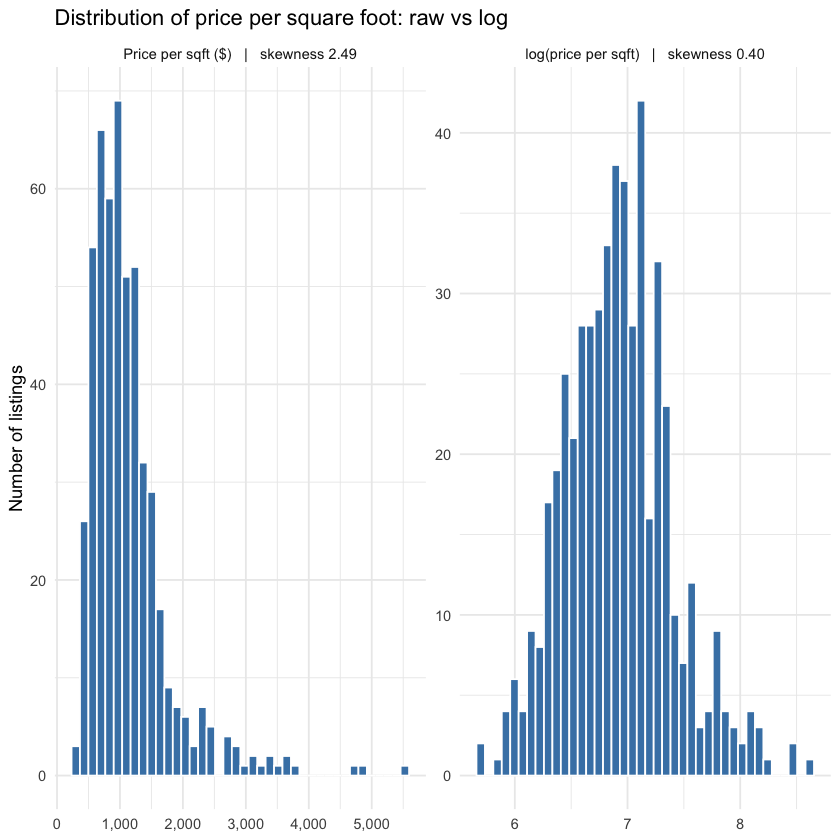

In [17]:
## Why log? Price per square foot is right-skewed, with a long tail of luxury listings (Seaport and Back Bay
## penthouses). The log scale is much more symmetric.
skew <- function(v) mean((v - mean(v))^3) / sd(v)^3
y <- merged_data$price_per_sqft[!is.na(merged_data$price_per_sqft)]

lab_raw <- sprintf("Price per sqft ($)   |   skewness %.2f", skew(y))
lab_log <- sprintf("log(price per sqft)   |   skewness %.2f", skew(log(y)))

plot_df <- bind_rows(data.frame(scale = lab_raw, value = y),
                     data.frame(scale = lab_log, value = log(y))) %>%
  mutate(scale = factor(scale, levels = c(lab_raw, lab_log)))

ggplot(plot_df, aes(x = value)) +
  geom_histogram(bins = 40, fill = "steelblue", colour = "white") +
  facet_wrap(~scale, scales = "free") +
  scale_x_continuous(labels = scales::label_comma()) +
  labs(title = "Distribution of price per square foot: raw vs log",
       x = NULL, y = "Number of listings") +
  theme_minimal()

cat(sprintf("Median $%s per sqft | 95th percentile $%s | max $%s | %d listings\n",
            format(round(median(y)), big.mark = ","), format(round(quantile(y, 0.95)), big.mark = ","),
            format(round(max(y)), big.mark = ","), length(y)))

In [18]:
## Model log(price per sqft) from here on. Rows without a square footage have no target and are dropped.
## price and estimated_monthly_payment stay in the data for scoring only; every model excludes them.
leak_cols <- c("price", "estimated_monthly_payment")

merged_data <- merged_data %>%
  filter(!is.na(price_per_sqft)) %>%
  mutate(log_pps = log(price_per_sqft)) %>%
  select(-price_per_sqft)

cat("Listings with a price per sqft:", nrow(merged_data), "\n")

Listings with a price per sqft: 515 


Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.”


`geom_smooth()` using formula = 'y ~ x'


Warning message:
“Removed 2 rows containing non-finite outside the scale range (`stat_smooth()`).”


Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


`geom_smooth()` using formula = 'y ~ x'


Warning message:
“Removed 2 rows containing non-finite outside the scale range (`stat_smooth()`).”


Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


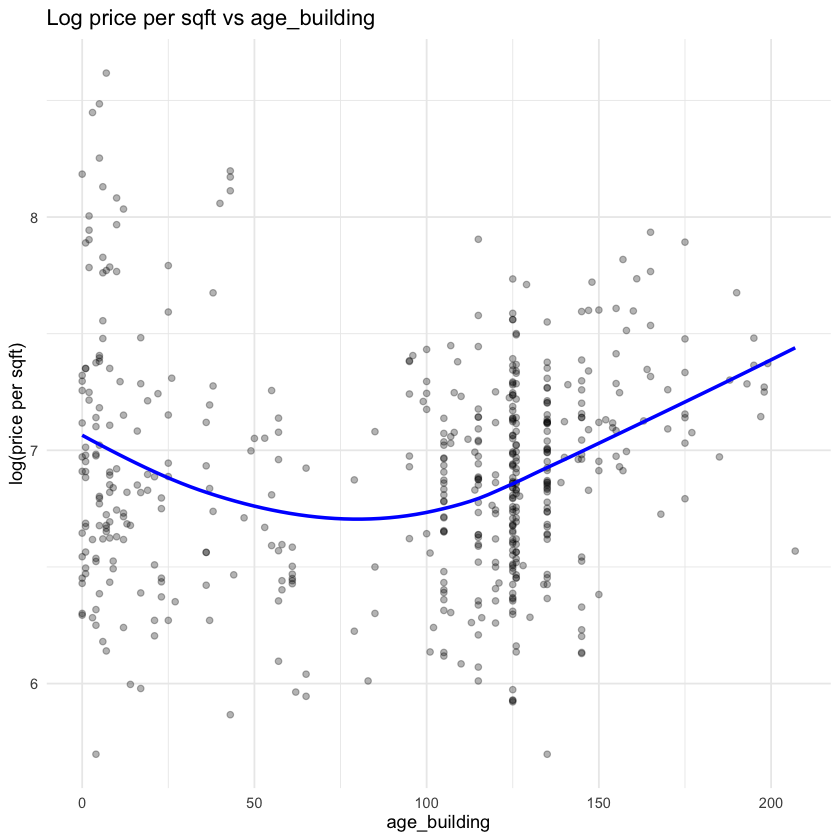

`geom_smooth()` using formula = 'y ~ x'


Warning message:
“Removed 70 rows containing non-finite outside the scale range
(`stat_smooth()`).”


Warning message:
“Removed 70 rows containing missing values or values outside the scale range
(`geom_point()`).”


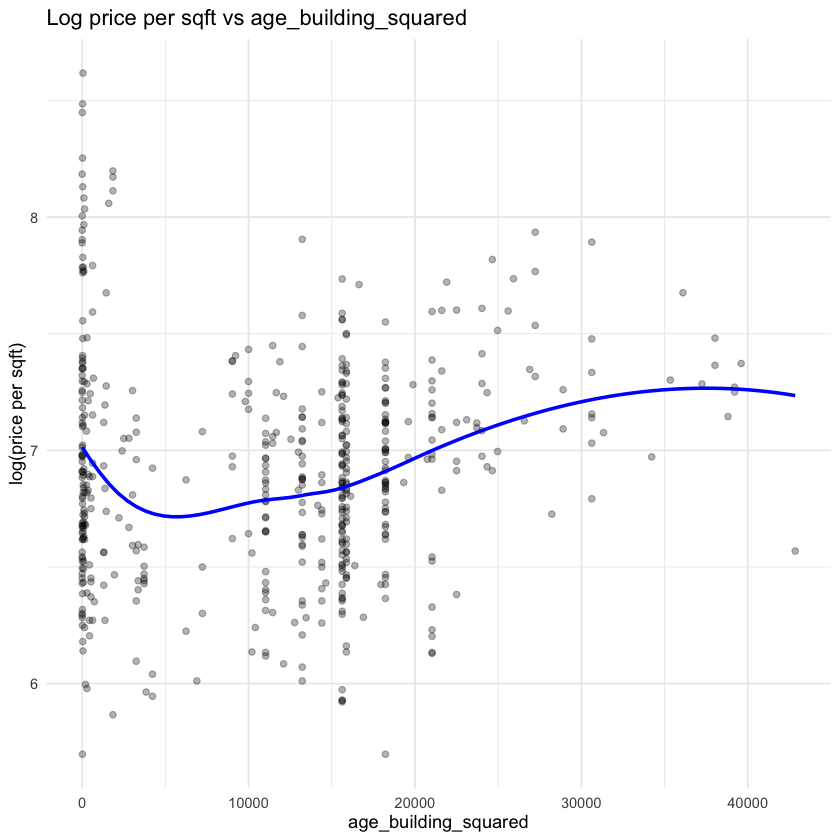

`geom_smooth()` using formula = 'y ~ x'


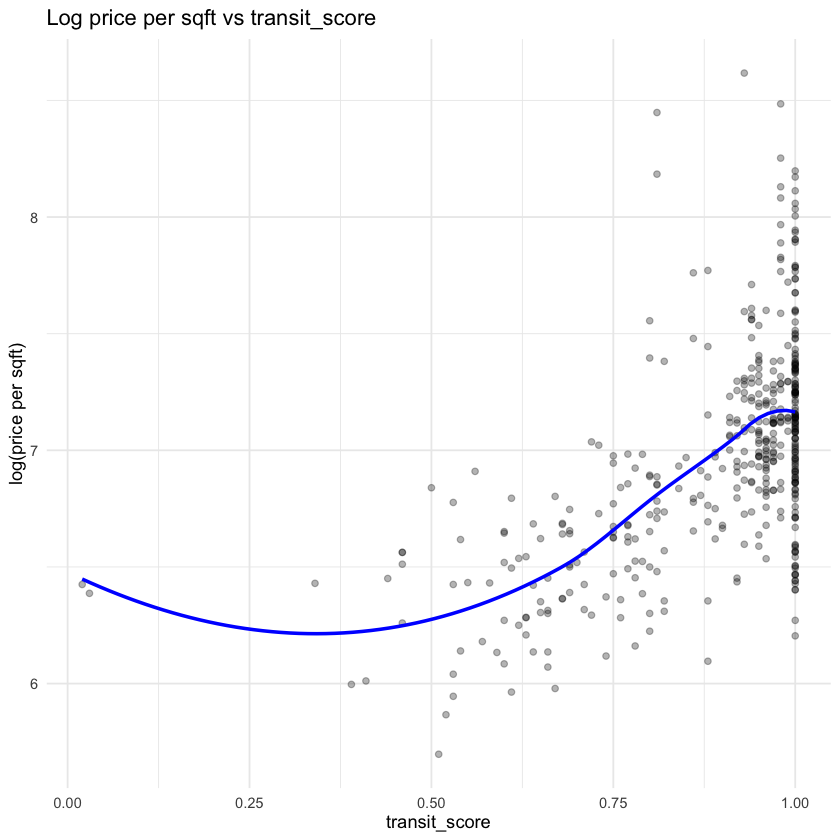

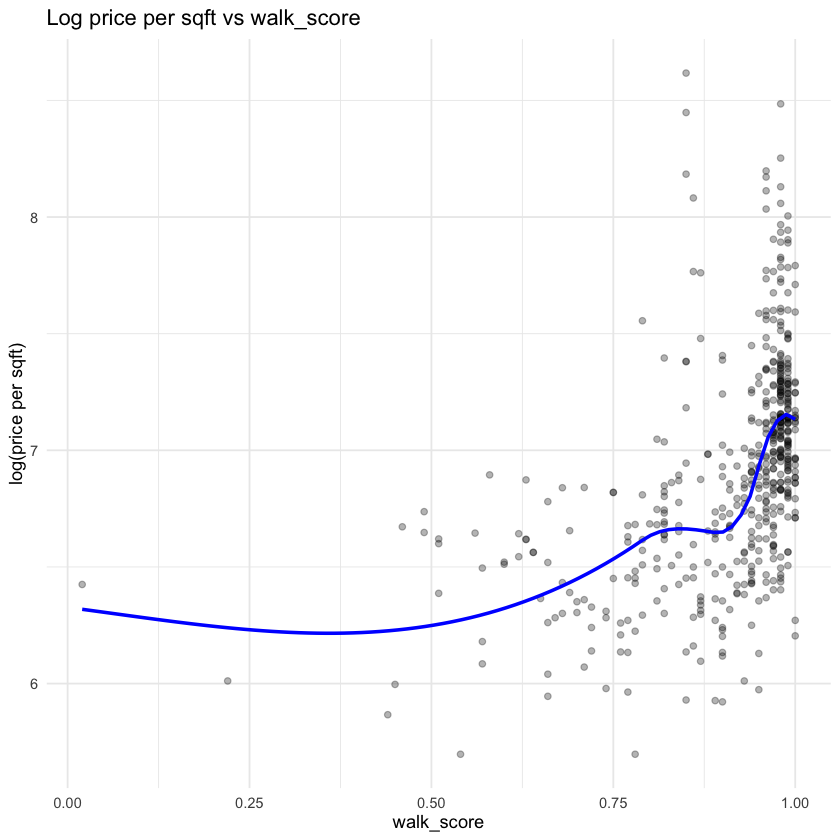

In [19]:
## We graph the following predictors (against the monthly payments) which may display nonlinearities, thus justifying the need for Random Forest.

merged_data <- merged_data %>%
  mutate(age_building_squared = age_building^2)

vars_1 <- c(
  "age_building",
  "age_building_squared",
  "transit_score",
  "walk_score"
)

for (v in vars_1) {
  p <- ggplot(merged_data, aes_string(x = v, y = "log_pps")) +
    geom_point(alpha = 0.3) +
    geom_smooth(method = "loess", se = FALSE, color = "blue") +
    labs(
      title = paste("Log price per sqft vs", v),
      x = v,
      y = "log(price per sqft)"
    ) +
    theme_minimal()

  print(p)
}

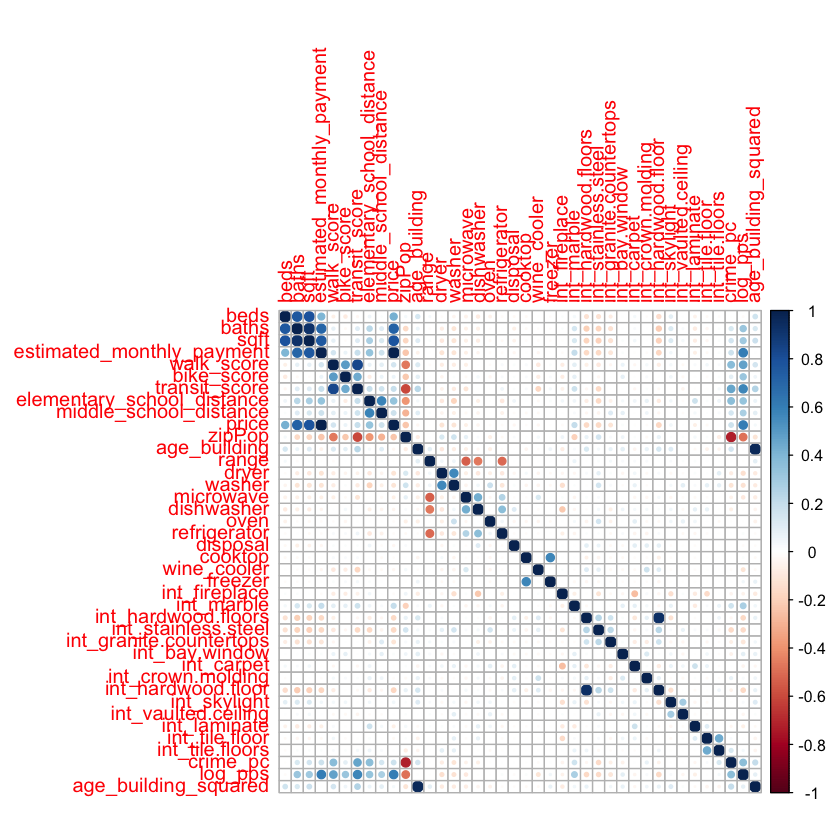

In [20]:
merged_data |>
  select(where(is.numeric)) |>
  cor(use = "pairwise.complete.obs") |>
  corrplot::corrplot()

`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


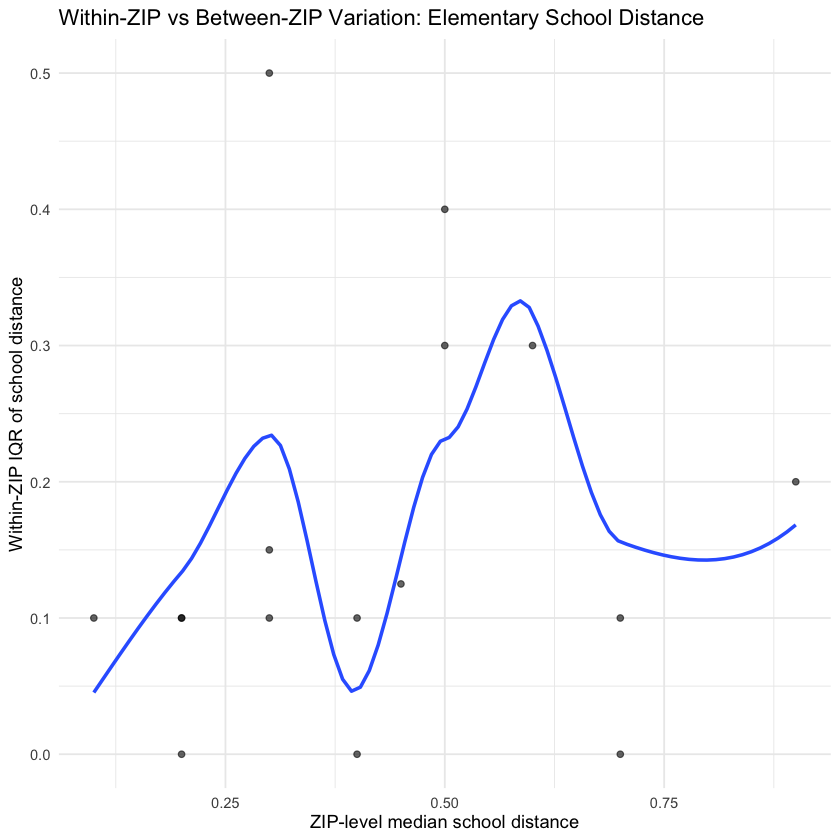

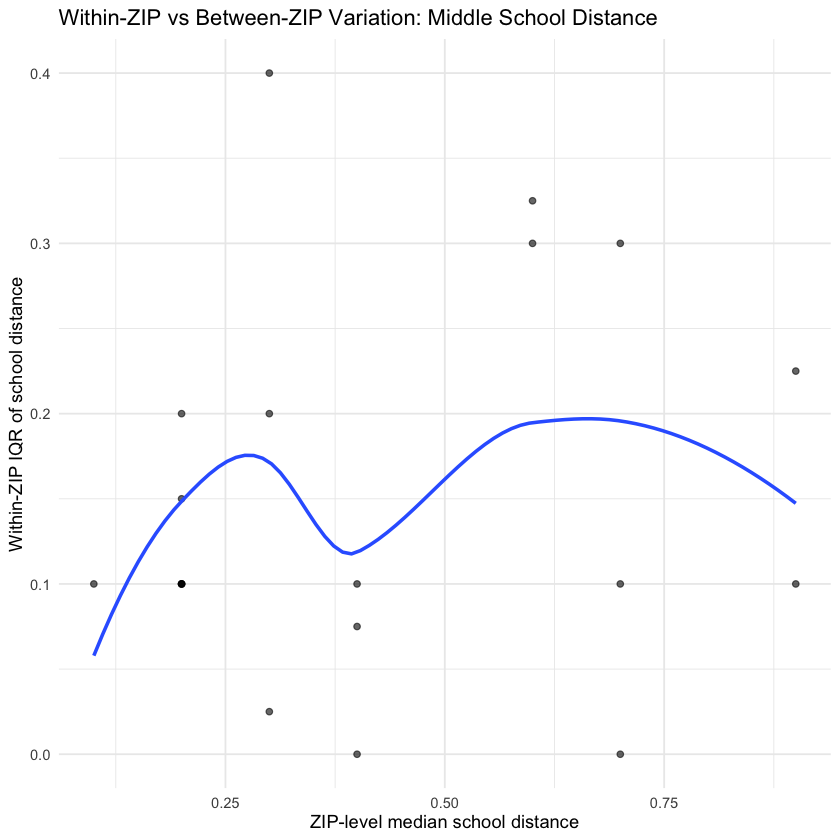

In [21]:
## Final plot of within-zipcode variation and between-zipcode variation in elementary and middle school distances.
## The ZIP-level medians of school distance vary substantially across areas, while within-ZIP dispersion is consistently low.
## This indicates strong spatial clustering, making ZIP-level median imputation appropriate and unlikely to distort the underlying
## distribution hence we impute my medan per zipcode.

make_zip_plot <- function(data, var, title_suffix) {
  zip_stats <- data %>%
    group_by(zip_code) %>%
    summarise(
      zip_median = median(.data[[var]], na.rm = TRUE),
      zip_IQR    = IQR(.data[[var]], na.rm = TRUE),
      n_obs      = sum(!is.na(.data[[var]])),
      .groups = "drop"
    ) %>%
    filter(n_obs >= 3)  # ensure stability

  ggplot(zip_stats, aes(x = zip_median, y = zip_IQR)) +
    geom_point(alpha = 0.6) +
    geom_smooth(method = "loess", se = FALSE) +
    labs(
      title = paste("Within-ZIP vs Between-ZIP Variation:", title_suffix),
      x = "ZIP-level median school distance",
      y = "Within-ZIP IQR of school distance"
    ) +
    theme_minimal()
}

# Elementary school
p_elem <- make_zip_plot(
  merged_data,
  "elementary_school_distance",
  "Elementary School Distance"
)

# Middle school
p_middle <- make_zip_plot(
  merged_data,
  "middle_school_distance",
  "Middle School Distance"
)

# Print plots
p_elem
p_middle

##Regressions: OLS, Elastic Net, Random Forest, XGBoost and AdaBoost

All models predict `log_pps` (log price per square foot). Scores are also reported on the monthly-payment scale.

In [22]:
## AdaBoost.R2 (Drucker, 1997) for regression, with shallow rpart trees as weak learners.
## Same algorithm as scikit-learn's AdaBoostRegressor (linear loss, weighted-median prediction).
adaboost_r2 <- function(x, y, n_learners = 100, maxdepth = 4, loss = "linear") {
  n <- length(y)
  w <- rep(1 / n, n)
  dat <- cbind(.y = y, x)
  trees <- list(); alpha <- numeric(0)
  for (m in seq_len(n_learners)) {
    idx <- sample.int(n, n, replace = TRUE, prob = w)              # weighted bootstrap
    tr  <- rpart::rpart(.y ~ ., data = dat[idx, ],
                        control = rpart::rpart.control(maxdepth = maxdepth, cp = 0))
    err <- abs(y - predict(tr, x))
    D   <- max(err)
    if (D == 0) {                                                  # perfect fit: stop
      trees[[length(trees) + 1]] <- tr; alpha <- c(alpha, 1); break
    }
    L    <- switch(loss, linear = err / D, square = (err / D)^2, exponential = 1 - exp(-err / D))
    Lbar <- sum(w * L)
    if (Lbar >= 0.5) {                                             # learner worse than chance: stop
      if (length(trees) == 0) { trees[[1]] <- tr; alpha <- 1 }
      break
    }
    beta <- Lbar / (1 - Lbar)
    trees[[length(trees) + 1]] <- tr
    alpha <- c(alpha, log(1 / beta))
    w <- w * beta^(1 - L)                                          # down-weight well-predicted rows
    w <- w / sum(w)
  }
  list(trees = trees, alpha = alpha)
}

predict_adaboost_r2 <- function(model, newdata, n_use = length(model$trees)) {
  n_use <- min(n_use, length(model$trees))                        # use only the first n_use learners
  model <- list(trees = model$trees[seq_len(n_use)], alpha = model$alpha[seq_len(n_use)])
  P <- sapply(model$trees, predict, newdata = newdata)             # rows = observations
  if (is.null(dim(P))) P <- matrix(P, nrow = nrow(newdata))
  apply(P, 1, function(p) {                                        # weighted median over learners
    o <- order(p)
    p[o][which(cumsum(model$alpha[o]) >= 0.5 * sum(model$alpha))[1]]
  })
}

In [23]:
set.seed(123)

# -----------------------------
# 1. Setup CV
# -----------------------------
K <- 5
merged_data <- merged_data %>%
  mutate(fold = sample(rep(1:K, length.out = n())))

# -----------------------------
# 2. Start CV Loop
# -----------------------------
fold_data <- list()  # imputed train/test sets per fold, reused by the tuning section below
fold_preds <- list() # out-of-fold predictions (log scale), used for the dollar-scale scores below

## Scores for a set of predictions of log price per sqft on outer fold k.
## RMSLE_pps: error on the log price-per-sqft scale (the model's own scale).
## Payment scale: payment_hat = exp(prediction) * sqft * (median payment/price ratio of the training folds), compared
## with the real monthly payment (RMSLE_pay, MAE and RMSE_usd in dollars).
score_fold <- function(k, pred_log_pps) {
  fd     <- fold_data[[k]]
  actual <- fd$test_num$log_pps
  log_pay_hat <- pred_log_pps + log(fd$test_sqft * fd$pay_ratio)
  pay_hat     <- exp(log_pay_hat)
  c(RMSLE_pps = sqrt(mean((actual - pred_log_pps)^2)),
    RMSLE_pay = sqrt(mean((log(fd$test_pay) - log_pay_hat)^2)),
    MAE       = mean(abs(fd$test_pay - pay_hat)),
    RMSE_usd  = sqrt(mean((fd$test_pay - pay_hat)^2)))
}

cv_results <- lapply(1:K, function(k) {

  # Split
  train <- merged_data %>% filter(fold != k)
  test  <- merged_data %>% filter(fold == k)

  # --- Imputation Step 1: Structural ---
  struct_stats <- train %>%
    group_by(property_type) %>%
    summarise(
      beds_med = median(beds, na.rm = TRUE),
      baths_med = median(baths, na.rm = TRUE),
      sqft_med = median(sqft, na.rm = TRUE),
      age_mean = mean(age_building, na.rm = TRUE),
      .groups = "drop"
    )

  train <- train %>% left_join(struct_stats, by = "property_type") %>%
    mutate(
      beds = ifelse(is.na(beds), beds_med, beds),
      baths = ifelse(is.na(baths), baths_med, baths),
      sqft = ifelse(is.na(sqft), sqft_med, sqft),
      age_building = ifelse(is.na(age_building), age_mean, age_building)
    ) %>% select(-ends_with("_med"), -age_mean)

  test <- test %>% left_join(struct_stats, by = "property_type") %>%
    mutate(
      beds = ifelse(is.na(beds), beds_med, beds),
      baths = ifelse(is.na(baths), baths_med, baths),
      sqft = ifelse(is.na(sqft), sqft_med, sqft),
      age_building = ifelse(is.na(age_building), age_mean, age_building)
    ) %>% select(-ends_with("_med"), -age_mean)

  # --- Imputation Step 2: ZIP Level ---
  zip_stats <- train %>%
    group_by(zip_code) %>%
    summarise(
      bike_med = median(bike_score, na.rm = TRUE),
      transit_med = median(transit_score, na.rm = TRUE),
      elem_med = median(elementary_school_distance, na.rm = TRUE),
      middle_med = median(middle_school_distance, na.rm = TRUE),
      .groups = "drop"
    )

  train <- train %>% left_join(zip_stats, by = "zip_code") %>%
    mutate(
      bike_score = ifelse(is.na(bike_score), bike_med, bike_score),
      transit_score = ifelse(is.na(transit_score), transit_med, transit_score),
      elementary_school_distance = ifelse(is.na(elementary_school_distance), elem_med, elementary_school_distance),
      middle_school_distance = ifelse(is.na(middle_school_distance), middle_med, middle_school_distance)
    ) %>% select(-ends_with("_med"))

  test <- test %>% left_join(zip_stats, by = "zip_code") %>%
    mutate(
      bike_score = ifelse(is.na(bike_score), bike_med, bike_score),
      transit_score = ifelse(is.na(transit_score), transit_med, transit_score),
      elementary_school_distance = ifelse(is.na(elementary_school_distance), elem_med, elementary_school_distance),
      middle_school_distance = ifelse(is.na(middle_school_distance), middle_med, middle_school_distance)
    ) %>% select(-ends_with("_med"))

  # --- Final Numeric Fallback (The "Hole" Filler) ---
  train <- train %>% mutate(across(where(is.numeric), ~ifelse(is.na(.x), median(.x, na.rm = TRUE), .x)))
  test  <- test %>% mutate(across(where(is.numeric), ~ifelse(is.na(.x), median(train[[cur_column()]], na.rm = TRUE), .x)))

  # --- Prepare Numeric-Only Sets for Modeling ---
  # This automatically excludes zip_code, property_type, and other text
  train_num <- train %>% select(where(is.numeric), -fold, -all_of(leak_cols))
  test_num  <- test %>% select(colnames(train_num))

  fold_data[[k]] <<- list(train_num = train_num, test_num = test_num,
                          test_sqft = test$sqft, test_pay = test$estimated_monthly_payment,   # for payment-scale scores
                          pay_ratio = median(train$estimated_monthly_payment / train$price))

  # -----------------------------
  # 3. Fit Models
  # -----------------------------

  # A. OLS
  ols_mod <- lm(log_pps ~ ., data = train_num)
  preds_ols <- predict(ols_mod, newdata = test_num)
  rmse_ols <- sqrt(mean((test_num$log_pps - preds_ols)^2, na.rm = TRUE))

  # B. Elastic Net (alpha = 0.5)
  train_x <- as.matrix(train_num %>% select(-log_pps))
  train_y <- train_num$log_pps
  test_x  <- as.matrix(test_num %>% select(-log_pps))

  elnet_cv <- cv.glmnet(train_x, train_y, alpha = 0.5)
  preds_en <- as.numeric(predict(elnet_cv, newx = test_x, s = "lambda.min"))
  rmse_en  <- sqrt(mean((test_num$log_pps - preds_en)^2, na.rm = TRUE))

  # C. Random Forest (ntree = 100 for speed)
  rf_mod  <- randomForest(log_pps ~ ., data = train_num, ntree = 100)
  preds_rf <- predict(rf_mod, newdata = test_num)
  rmse_rf  <- sqrt(mean((test_num$log_pps - preds_rf)^2, na.rm = TRUE))

  # D. XGBoost (fixed, untuned hyperparameters)
  set.seed(123 + k)
  xgb_mod <- xgboost::xgb.train(
    params = list(objective = "reg:squarederror", eta = 0.05, max_depth = 4,
                  subsample = 0.8, colsample_bytree = 0.8),
    data = xgboost::xgb.DMatrix(data = train_x, label = train_y),
    nrounds = 300, verbose = 0
  )
  preds_xgb <- predict(xgb_mod, xgboost::xgb.DMatrix(data = test_x))
  rmse_xgb  <- sqrt(mean((test_num$log_pps - preds_xgb)^2, na.rm = TRUE))

  # E. AdaBoost.R2 (fixed, untuned hyperparameters)
  set.seed(123 + k)
  ada_mod   <- adaboost_r2(train_num %>% select(-log_pps), train_y,
                           n_learners = 100, maxdepth = 4)
  preds_ada <- predict_adaboost_r2(ada_mod, test_num %>% select(-log_pps))
  rmse_ada  <- sqrt(mean((test_num$log_pps - preds_ada)^2, na.rm = TRUE))

  fold_preds[[k]] <<- list(actual = test_num$log_pps, OLS = preds_ols, ElNet = preds_en,
                           RF = preds_rf, XGB = preds_xgb, Ada = preds_ada)

  # Return results for this fold
  data.frame(fold = k, OLS = rmse_ols, ElNet = rmse_en, RF = rmse_rf, XGB = rmse_xgb, Ada = rmse_ada)
})

# -----------------------------
# 4. Final Comparison Results
# -----------------------------
final_comparison <- bind_rows(cv_results)

print("--- RMSLE of log price per sqft, per fold ---")
print(final_comparison)

print("--- Mean RMSLE Summary ---")
final_comparison %>%
  summarise(across(c(OLS, ElNet, RF, XGB, Ada), list(mean = mean, sd = sd)))

## Same predictions, converted back to dollars
cv_scores <- bind_rows(lapply(seq_along(fold_preds), function(k)
  bind_rows(lapply(setdiff(names(fold_preds[[k]]), "actual"), function(m)
    data.frame(fold = k, model = m, t(score_fold(k, fold_preds[[k]][[m]])))))))

print("--- Mean scores by model (payment-scale: RMSLE_pay, MAE and RMSE in dollars) ---")
cv_scores %>%
  group_by(model) %>%
  summarise(across(c(RMSLE_pps, RMSLE_pay, MAE, RMSE_usd), ~ round(mean(.x), 3)), .groups = "drop") %>%
  arrange(match(model, c("OLS", "ElNet", "RF", "XGB", "Ada"))) %>%
  as.data.frame()

Warning message in predict.lm(ols_mod, newdata = test_num):
“prediction from rank-deficient fit; attr(*, "non-estim") has doubtful cases”


Warning message in predict.lm(ols_mod, newdata = test_num):
“prediction from rank-deficient fit; attr(*, "non-estim") has doubtful cases”


[1] "--- RMSLE of log price per sqft, per fold ---"


  fold       OLS     ElNet        RF       XGB       Ada
1    1 0.3356786 0.3332906 0.2387079 0.2277203 0.2652313
2    2 0.3093165 0.3020866 0.2319382 0.2349070 0.2603352
3    3 0.3238399 0.3260402 0.2545304 0.2753335 0.2790753
4    4 0.3615333 0.3286478 0.2334556 0.2472088 0.2606494
5    5 0.3789633 0.3977560 0.3042337 0.2816753 0.3052519


[1] "--- Mean RMSLE Summary ---"


OLS_mean,OLS_sd,ElNet_mean,ElNet_sd,RF_mean,RF_sd,XGB_mean,XGB_sd,Ada_mean,Ada_sd
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.3418663,0.02822104,0.3375642,0.0357501,0.2525732,0.03023315,0.253369,0.02408492,0.2741086,0.01900155


[1] "--- Mean scores by model (payment-scale: RMSLE_pay, MAE and RMSE in dollars) ---"


model,RMSLE_pps,RMSLE_pay,MAE,RMSE_usd
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
OLS,0.342,0.341,5611.953,14652.31
ElNet,0.338,0.336,5552.719,15107.66
RF,0.253,0.256,4238.109,11883.13
XGB,0.253,0.258,4053.315,11333.69
Ada,0.274,0.277,4462.449,11767.05


## Hyperparameter tuning (nested cross-validation)

The comparison above uses fixed hyperparameters for XGBoost and AdaBoost. Here Random Forest, XGBoost and AdaBoost are tuned on `log_pps` (RMSLE_pps is on that log scale; the payment-scale scores convert predictions back as described above) with **nested** CV so the tuned scores are not optimistic:

- **Outer loop:** the same 5 folds as above. Each fold's held-out rows are never used for tuning.
- **Inner loop:** hyperparameters are chosen using only that fold's training rows, with 5-fold CV (XGBoost, AdaBoost) or out-of-bag (OOB) error (Random Forest). OOB error needs no extra folds, because each tree is scored on the rows left out of its own bootstrap sample.
- The best setting is refit on the full outer-training set and scored on the held-out fold.

Search spaces: XGBoost = learning rate, tree depth, row/column subsampling, min child weight (the number of rounds is chosen by early stopping); AdaBoost = tree depth, loss, number of learners; Random Forest = `mtry`, `nodesize`.

Note: missing values were imputed using each outer-training set, so inner validation rows influence those medians slightly. This is negligible and does not touch the held-out outer fold.

*This cell block takes roughly 10-15 minutes to run.*

In [24]:
inner_K <- 5

xgb_grid <- expand.grid(eta = c(0.03, 0.1), max_depth = c(2, 4, 6), subsample = c(0.7, 1),
                        colsample_bytree = c(0.6, 1), min_child_weight = c(1, 5))
ada_grid <- expand.grid(maxdepth = c(2, 3, 4, 6), loss = c("linear", "square", "exponential"),
                        stringsAsFactors = FALSE)
ada_n_learners <- c(50, 100, 200)
rf_grid  <- expand.grid(mtry = c(6, 12, 18, 24, 30), nodesize = c(1, 3, 5))

tune_models <- function(train_num) {
  x <- as.matrix(train_num %>% select(-log_pps))
  y <- train_num$log_pps
  xdf <- as.data.frame(x)
  inner <- split(sample(seq_along(y)), rep(seq_len(inner_K), length.out = length(y)))

  # XGBoost: xgb.cv with early stopping picks the number of rounds for every candidate setting
  dtr <- xgboost::xgb.DMatrix(data = x, label = y)
  xgb_res <- t(sapply(seq_len(nrow(xgb_grid)), function(i) {
    cv  <- xgboost::xgb.cv(params = c(list(objective = "reg:squarederror"), as.list(xgb_grid[i, ])),
                           data = dtr, nrounds = 1000, folds = inner,
                           early_stopping_rounds = 30, verbose = 0)
    log <- cv$evaluation_log
    j   <- which.min(log$test_rmse_mean)
    c(rmse = log$test_rmse_mean[j], nrounds = log$iter[j])
  }))

  # AdaBoost: fit once with the most learners, then score the first 50 / 100 / 200 of them
  ada_res <- do.call(rbind, lapply(seq_len(nrow(ada_grid)), function(g) {
    rm <- sapply(inner, function(te) {
      fit <- adaboost_r2(xdf[-te, ], y[-te], n_learners = max(ada_n_learners),
                         maxdepth = ada_grid$maxdepth[g], loss = ada_grid$loss[g])
      sapply(ada_n_learners, function(m)
        sqrt(mean((y[te] - predict_adaboost_r2(fit, xdf[te, ], n_use = m))^2)))
    })
    data.frame(maxdepth = ada_grid$maxdepth[g], loss = ada_grid$loss[g],
               n_learners = ada_n_learners, rmse = rowMeans(rm))
  }))

  # Random Forest: out-of-bag (OOB) error is a built-in stand-in for inner CV. Each tree is scored on the rows left
  # out of its bootstrap sample, so no extra folds are needed; sqrt() of the OOB mean squared error puts it on the
  # same RMSLE scale as the other models.
  rf_res <- cbind(rf_grid, rmse = sapply(seq_len(nrow(rf_grid)), function(i)
    sqrt(tail(randomForest(x, y, ntree = 300, mtry = rf_grid$mtry[i],
                           nodesize = rf_grid$nodesize[i])$mse, 1))))

  bx <- which.min(xgb_res[, "rmse"])
  list(xgb = c(as.list(xgb_grid[bx, ]), nrounds = unname(xgb_res[bx, "nrounds"])),
       ada = as.list(ada_res[which.min(ada_res$rmse), c("maxdepth", "loss", "n_learners")]),
       rf  = as.list(rf_res[which.min(rf_res$rmse), c("mtry", "nodesize")]))
}

In [25]:
set.seed(123)

## Runs the nested tuning on every outer fold (target = log_pps). Scores are RMSLE; the out-of-fold predictions
## are kept so they can also be scored in dollars.
run_nested_tuning <- function() {
  lapply(seq_along(fold_data), function(k) {
    set.seed(123 + k)
    tr <- fold_data[[k]]$train_num
    te <- fold_data[[k]]$test_num
    best <- tune_models(tr)

    xtr <- as.matrix(tr %>% select(-log_pps)); ytr <- tr$log_pps
    xte <- as.matrix(te %>% select(colnames(xtr)))

    rf  <- randomForest(xtr, ytr, ntree = 500, mtry = best$rf$mtry, nodesize = best$rf$nodesize)
    xg  <- xgboost::xgb.train(
      params = c(list(objective = "reg:squarederror"), best$xgb[names(best$xgb) != "nrounds"]),
      data = xgboost::xgb.DMatrix(data = xtr, label = ytr), nrounds = best$xgb$nrounds, verbose = 0)
    ada <- adaboost_r2(as.data.frame(xtr), ytr, n_learners = best$ada$n_learners,
                       maxdepth = best$ada$maxdepth, loss = best$ada$loss)

    preds  <- data.frame(RF  = predict(rf, xte),
                         XGB = predict(xg, xgboost::xgb.DMatrix(data = xte)),
                         Ada = predict_adaboost_r2(ada, as.data.frame(xte)))
    actual <- te$log_pps
    rmsle  <- function(p) sqrt(mean((actual - p)^2))

    list(scores = data.frame(fold = k, RF_tuned = rmsle(preds$RF),
                             XGB_tuned = rmsle(preds$XGB), Ada_tuned = rmsle(preds$Ada)),
         preds = preds, actual = actual, best = best)
  })
}

tuned <- run_nested_tuning()

tuned_scores <- bind_rows(lapply(tuned, `[[`, "scores"))

tuning_comparison <- final_comparison %>%
  select(fold, RF, XGB, Ada) %>%
  left_join(tuned_scores, by = "fold")

print("--- RMSLE per fold: fixed vs tuned ---")
print(tuning_comparison)

print("--- Mean RMSLE: fixed vs tuned ---")
tuning_comparison %>% summarise(across(-fold, list(mean = mean, sd = sd)))

print("--- Hyperparameters chosen in each outer fold ---")
bind_rows(lapply(seq_along(tuned), function(k) {
  b <- tuned[[k]]$best
  data.frame(fold = k,
             xgb_eta = b$xgb$eta, xgb_depth = b$xgb$max_depth, xgb_subsample = b$xgb$subsample,
             xgb_colsample = b$xgb$colsample_bytree, xgb_min_child = b$xgb$min_child_weight,
             xgb_rounds = b$xgb$nrounds,
             ada_depth = b$ada$maxdepth, ada_loss = b$ada$loss, ada_learners = b$ada$n_learners,
             rf_mtry = b$rf$mtry, rf_nodesize = b$rf$nodesize)
}))

print("--- Mean scores, fixed vs tuned (payment-scale in dollars) ---")
tuned_scores_usd <- bind_rows(lapply(seq_along(tuned), function(k)
  bind_rows(lapply(names(tuned[[k]]$preds), function(m)
    data.frame(fold = k, model = paste0(m, "_tuned"),
               t(score_fold(k, tuned[[k]]$preds[[m]])))))))
bind_rows(cv_scores %>% filter(model %in% c("RF", "XGB", "Ada")), tuned_scores_usd) %>%
  group_by(model) %>%
  summarise(across(c(RMSLE_pps, RMSLE_pay, MAE, RMSE_usd), ~ round(mean(.x), 3)), .groups = "drop") %>%
  arrange(match(model, c("RF", "RF_tuned", "XGB", "XGB_tuned", "Ada", "Ada_tuned"))) %>%
  as.data.frame()

[1] "--- RMSLE per fold: fixed vs tuned ---"


  fold        RF       XGB       Ada  RF_tuned XGB_tuned Ada_tuned
1    1 0.2387079 0.2277203 0.2652313 0.2383736 0.2196280 0.2546946
2    2 0.2319382 0.2349070 0.2603352 0.2306530 0.2376149 0.2394866
3    3 0.2545304 0.2753335 0.2790753 0.2586052 0.2462235 0.2694034
4    4 0.2334556 0.2472088 0.2606494 0.2272234 0.2446066 0.2438126
5    5 0.3042337 0.2816753 0.3052519 0.2997886 0.2871205 0.2909519


[1] "--- Mean RMSLE: fixed vs tuned ---"


RF_mean,RF_sd,XGB_mean,XGB_sd,Ada_mean,Ada_sd,RF_tuned_mean,RF_tuned_sd,XGB_tuned_mean,XGB_tuned_sd,Ada_tuned_mean,Ada_tuned_sd
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.2525732,0.03023315,0.253369,0.02408492,0.2741086,0.01900155,0.2509288,0.02990357,0.2470387,0.02476534,0.2596698,0.02095755


[1] "--- Hyperparameters chosen in each outer fold ---"


fold,xgb_eta,xgb_depth,xgb_subsample,xgb_colsample,xgb_min_child,xgb_rounds,ada_depth,ada_loss,ada_learners,rf_mtry,rf_nodesize
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,0.03,4,1.0,0.6,1,288,6,exponential,200,18,1
2,0.03,6,1.0,0.6,1,236,6,square,100,18,1
3,0.03,6,0.7,0.6,5,310,6,exponential,200,18,5
4,0.03,4,0.7,0.6,1,294,6,square,200,12,1
5,0.03,6,0.7,1.0,5,226,6,exponential,100,18,3


[1] "--- Mean scores, fixed vs tuned (payment-scale in dollars) ---"


model,RMSLE_pps,RMSLE_pay,MAE,RMSE_usd
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
RF,0.253,0.256,4238.109,11883.13
RF_tuned,0.251,0.253,4171.492,11594.74
XGB,0.253,0.258,4053.315,11333.69
XGB_tuned,0.247,0.251,3996.418,11152.70
Ada,0.274,0.277,4462.449,11767.05
Ada_tuned,0.260,0.262,4097.411,10765.60


mtry = 12  OOB error = 0.05585872 
Searching left ...
mtry = 8 	OOB error = 0.05738947 
-0.02740383 0.01 
Searching right ...
mtry = 18 	OOB error = 0.05414683 
0.0306469 0.01 
mtry = 27 	OOB error = 0.0566477 
-0.04618691 0.01 


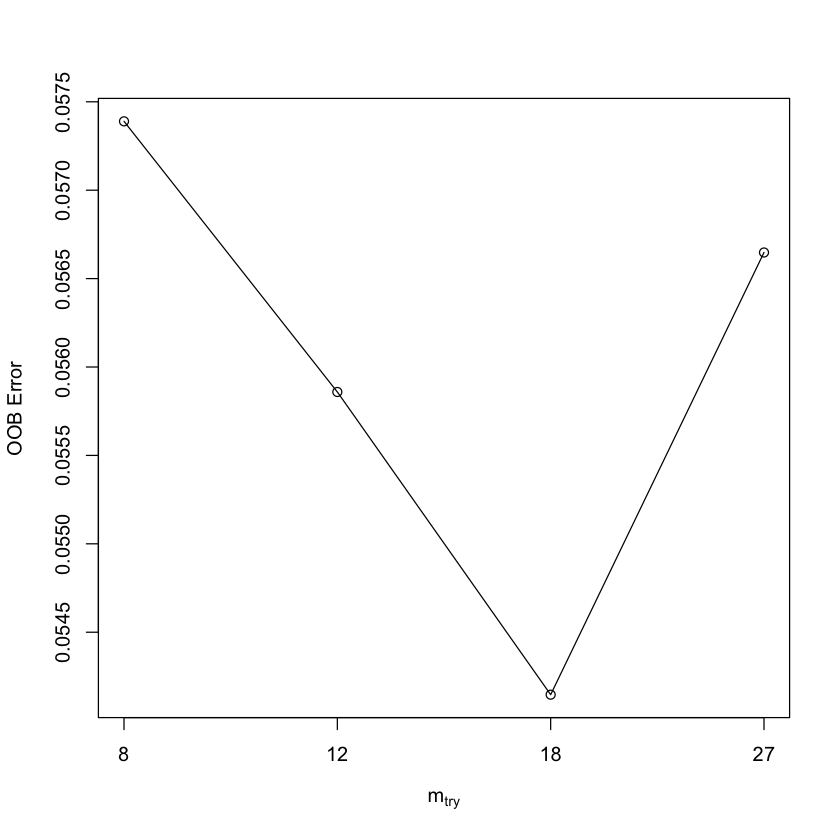

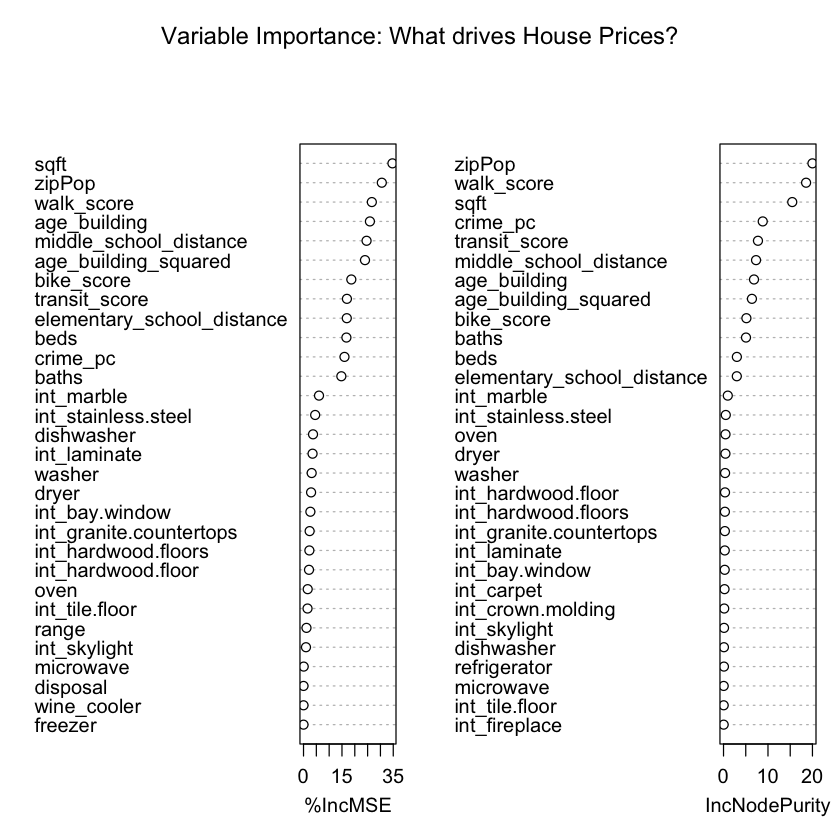

In [26]:
# 1. Re-prepare the full data (using the same logic as the loop)
# We'll use the whole dataset for the final importance and tuning
full_train_num <- merged_data %>%
  mutate(across(where(is.numeric), ~ifelse(is.na(.x), median(.x, na.rm = TRUE), .x))) %>%
  select(where(is.numeric), -fold, -all_of(leak_cols))

# 2. Automated Tuning for mtry
# tuneRF chooses mtry by out-of-bag (OOB) error. Each tree is grown on a bootstrap sample, which leaves out about
# a third of the rows; predicting those rows using only the trees that never saw them gives an error estimate that
# works like cross-validation without a separate hold-out set. For regression, tuneRF reports the OOB mean squared
# error (here on the log price-per-sqft scale). It starts at the default mtry and keeps stepping up or down by
# stepFactor for as long as the OOB error improves by at least `improve`.
set.seed(123)
best_mtry_search <- tuneRF(
  x = full_train_num %>% select(-log_pps),
  y = full_train_num$log_pps,
  stepFactor = 1.5,
  improve = 0.01,
  ntreeTry = 200,
  trace = TRUE,
  plot = TRUE
)

# 3. Identify the best mtry
best_mtry <- as.numeric(rownames(best_mtry_search)[which.min(best_mtry_search[,2])])

# 4. Fit the Final Optimised Model
final_rf_optimised <- randomForest(
  log_pps ~ .,
  data = full_train_num,
  mtry = best_mtry,
  ntree = 500, # more trees for the final model
  importance = TRUE
)

# 5. Visualise feature importance
varImpPlot(final_rf_optimised, main = "Variable Importance: What drives House Prices?")

## Comments on the Random Forest

Square footage is still the most important predictor of log price per square foot, but only narrowly: zip-code population and walkability (walk score) come close behind, followed by building age and middle-school distance. This is the main difference from a model of total price, where size dominates mechanically. Once size is removed from the target, location and neighbourhood characteristics carry most of the predictive weight.

Walk, transit and bike scores are strongly correlated (walk and transit: 0.83), so they share importance, and each is individually understated. The same is true of building age and its square (correlation 0.96), which together make building age one of the strongest predictors. This is consistent with a non-linear effect in which both recent and old buildings command a premium, for reasons of modernity or aesthetic value, although importance scores alone cannot confirm that shape. Baths and beds rank in the lower half of the top dozen once size is removed.

Two predictors take a single value per zip code (27 distinct values): zip-code population and crime per capita. Because the zip code itself is not a model input, they partly act as zip-code identifiers. The importance of zip-code population therefore likely reflects *which* neighbourhood a listing is in, not population as such. Crime per capita ranks around 10th of 37, on a par with beds and just behind elementary-school distance (exact ranks move by a place or two between random seeds). It is less important than we expected, but not negligible, and its effect cannot be separated from other zip-level characteristics.

Middle-school distance is consistently among the top six predictors, while elementary-school distance ranks lower (between 7th and 11th). High-school distance was dropped because too many values were missing, so it cannot be compared. One plausible reading is that many elementary schools feed into a few middle schools, making middle-school proximity a more salient factor in families' decisions. This remains a hypothesis.

Importance measures predictive contribution, not causal effect. To aid interpretability, we approximate the random forest with a shallow regression tree that captures the dominant prediction patterns.

Shallow tree: 7 leaves, cross-validated R2 = 0.43 | Random Forest out-of-bag R2 = 0.76


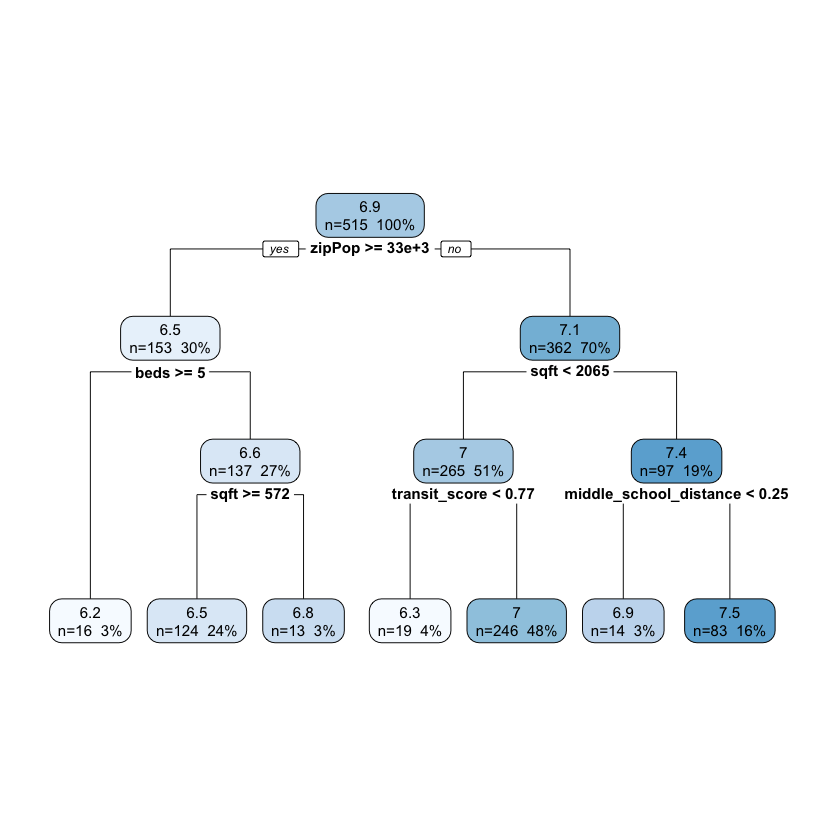

In [27]:
# Approximate the forest with a single shallow CART tree, fitted to the SAME data.
# maxdepth = 3 keeps the tree readable (at most 8 leaves); cp = 0.005 stops splits that add little.
set.seed(123)
single_tree <- rpart(
  log_pps ~ .,
  data = full_train_num,
  method = "anova",
  control = rpart.control(maxdepth = 3, cp = 0.005)
)

## Node values are log(price per sqft)
rpart.plot(single_tree, type = 2, extra = 101)

## How much variation the shallow tree captures, compared with the forest (out-of-bag R-squared)
tree_cp <- single_tree$cptable
cat(sprintf("Shallow tree: %d leaves, cross-validated R2 = %.2f | Random Forest out-of-bag R2 = %.2f\n",
            sum(single_tree$frame$var == "<leaf>"),
            1 - tree_cp[nrow(tree_cp), "xerror"],
            tail(final_rf_optimised$rsq, 1)))

In [28]:
## Export our constructed dataset to .csv (price per sqft is added back for convenience)
write.csv(merged_data %>% mutate(price_per_sqft = exp(log_pps)),
          "FinalProjectDataset.csv", row.names = FALSE)

## Robustness: modelling the monthly payment instead

The same cleaning, log transform, folds and models were also run with `log(estimated monthly payment)` as the target, to check that the choice of target does not drive the conclusions. Scores below are on the **monthly-payment scale** for both targets (for the price-per-sqft models, predictions are converted back to a payment as price per sqft x sqft x the typical payment/price ratio). 5-fold CV, fixed hyperparameters; RMSLE is the error on the log scale and MAE is in dollars.

| Model | Payment target: RMSLE | Payment target: MAE ($) | Price-per-sqft target: RMSLE | Price-per-sqft target: MAE ($) |
|---|---|---|---|---|
| OLS | 0.454 | 11,066 | 0.341 | 5,612 |
| Elastic Net | 0.450 | 11,237 | 0.336 | 5,553 |
| Random Forest | 0.286 | 4,551 | 0.256 | 4,238 |
| XGBoost | 0.253 | 3,735 | 0.258 | 4,053 |
| AdaBoost | 0.319 | 4,615 | 0.277 | 4,462 |

- The linear models gain the most from the price-per-sqft target: their dollar error roughly halves, because they no longer have to learn a multiplicative size effect.
- Random Forest and AdaBoost improve modestly. XGBoost is the one model that does slightly better on the payment target (MAE $3,735 vs $4,053), a gap within the fold-to-fold noise (standard deviation of roughly 0.025 RMSLE).
- Tuning changed the tree models' scores by at most about 0.014 RMSLE under either target.
- Price per square foot was chosen as the main target because it gives a fairer comparison across models and, by removing the mechanical size effect, shows what location and neighbourhood data add.

*The two setups use 515 (price per sqft) and 517 (payment) listings, because listings without a square footage have no price per square foot, so the cross-validation folds differ slightly.*

## Conclusions and limitations

**Findings**
- XGBoost is the best model, with a typical error of roughly a quarter of the price per square foot (RMSLE about 0.25) against about a third for the linear baselines.
- Hyperparameter tuning adds little (at most about 0.014 RMSLE); the fixed settings were already close to the best this sample supports.
- Without the size effect, neighbourhood characteristics (walkability, school proximity, zip-level variables) carry as much predictive signal as the property's own features.

**Limitations**
- **Small sample:** 515 listings, about 78% of them condos. Fold-to-fold variation is large (standard deviation around 0.02-0.03 RMSLE), so the differences among the three tree models are not statistically meaningful.
- **Asking prices:** the data are listing prices at one point in time, not transaction prices, and the monthly payment is an estimate.
- **Zip-level features:** crime and population take only 27 distinct values, so their effects cannot be separated from other neighbourhood effects. The 2020 Census is applied to 2025 listings.
- **Interpretation:** variable importance measures predictive contribution, not causal effect.